In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from scipy import stats


In [15]:
df = pd.read_csv('data/regime_change/bm_n6000_GenBIN_Fr0.950_mpri15.300_spri0.400_msec1.000_ssec1.330_WarmA0.000_c0_w_0.csv')
df.head(10)

,x
0,15.598274
1,14.727003
2,17.004732
3,14.793713
4,14.668192
5,16.132158
6,15.174631
7,15.305058
8,15.803203
9,16.133813


In [16]:
df.shape

(6000, 1)

In [17]:
df.describe()

,x
count,6000.000000
mean,15.366853
std,0.569694
min,12.873629
25%,15.038025
50%,15.313992
75%,15.612950
max,19.699993


In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x       6000 non-null   float64
dtypes: float64(1)
memory usage: 47.0 KB


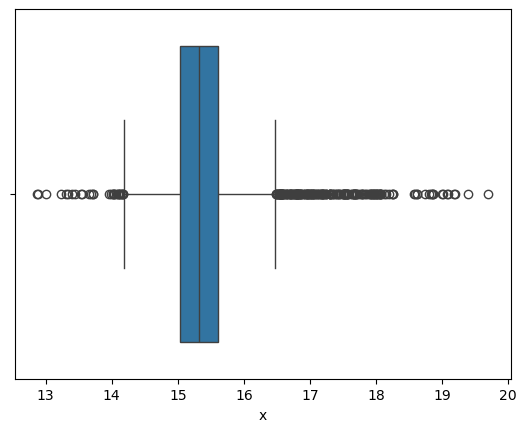

In [19]:
for i in df.select_dtypes(include = "number").columns:
    sns.boxplot(data = df, x = i)
    plt.show()

In [20]:
scale = StandardScaler()
df_scaled = pd.DataFrame(scale.fit_transform(df), columns=df.columns, index=df.index)
df_scaled

,x
0,0.406253
1,-1.123241
2,2.875255
3,-1.006133
4,-1.226483
...,...
5995,-0.528504
5996,0.112151
5997,-0.433197
5998,-1.533060


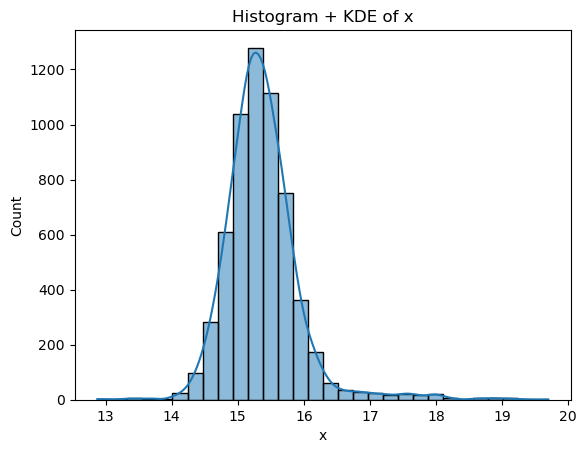

In [21]:
col = df.columns[0]

sns.histplot(df[col], kde=True, bins=30)
plt.title("Histogram + KDE of " + col)
plt.show()

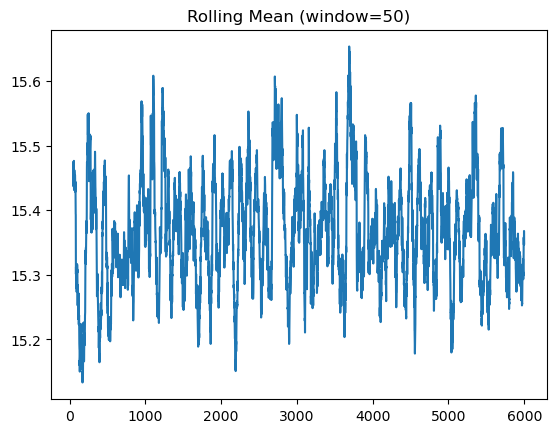

In [22]:
df['roll_mean_50'] = df[col].rolling(window=50).mean()
plt.plot(df['roll_mean_50'])
plt.title("Rolling Mean (window=50)")
plt.show()

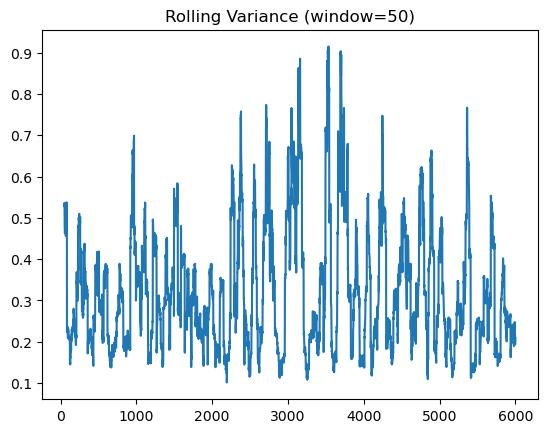

In [23]:
df['rollingVariance'] = df[col].rolling(window=50).var()
plt.plot(df['rollingVariance'])
plt.title("Rolling Variance (window=50)")
plt.show()

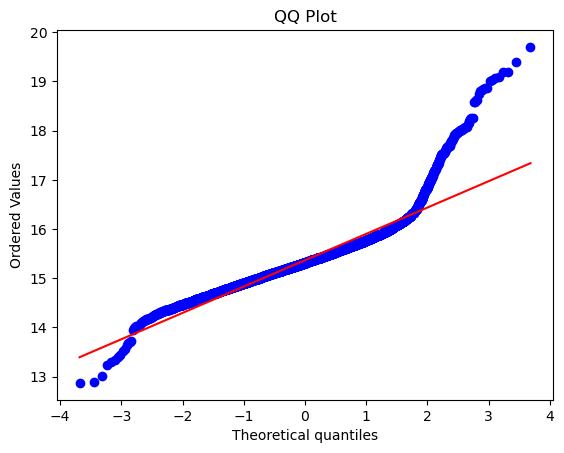

In [25]:
stats.probplot(df[col], dist="norm", plot=plt)
plt.title("QQ Plot")
plt.show()

In [26]:
Q1 = df[col].quantile(0.25)
Q3 = df[col].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5*IQR
upper = Q3 + 1.5*IQR
outliers = df[(df[col] < lower) | (df[col] > upper)]
outliers.head(), len(outliers)

(             x  roll_mean_50  rollingVariance
 2    17.004732           NaN              NaN
 33   19.197038           NaN              NaN
 72   17.036653     15.454583         0.517483
 133  14.150033     15.159750         0.184269
 170  14.024315     15.133272         0.280102,
 223)